In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

In [3]:
input_path = "/mnt/c/Users/jefferson.faria/Documents/GitHub/ic-2025/dataSet/data-preProcessed/pre_processing/espectros_msc.csv"
output_dir = "/mnt/c/Users/jefferson.faria/Documents/GitHub/ic-2025/dataSet/data-preProcessed/pre_processing"
output_path = os.path.join(output_dir, 'espectros_transformada_log.csv')



In [4]:
df = pd.read_csv(input_path)
data = df.values

In [5]:
data[data <= 0] = 1e-6
data_log = -np.log(data)

In [6]:
df_espectros = pd.DataFrame(data_log, columns=df.columns)

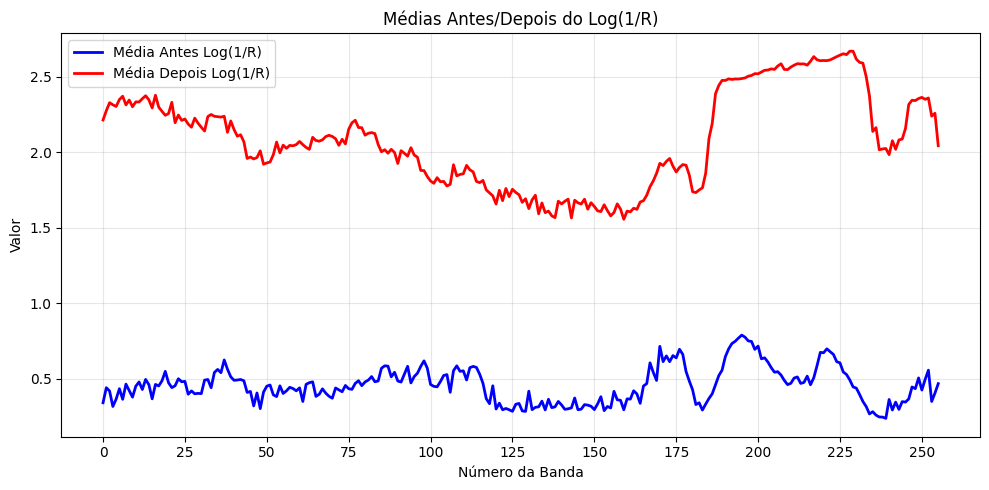

In [8]:
plt.figure(figsize=(10, 5))

# Plotar apenas as médias primeiro para verificar
media_antes = data.mean(axis=0)
media_depois = data_log.mean(axis=0)

bandas_numeros = np.arange(len(media_antes))

plt.plot(bandas_numeros, media_antes, label='Média Antes Log(1/R)', linewidth=2, color='blue')
plt.plot(bandas_numeros, media_depois, label='Média Depois Log(1/R)', linewidth=2, color='red')

plt.xlabel('Número da Banda')
plt.ylabel('Valor')
plt.title('Médias Antes/Depois do Log(1/R)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(bandas_numeros[::len(bandas_numeros)//10])

plt.tight_layout()
plt.show()

In [ ]:
df_espectros.to_csv(output_path, index=False)
print("Arquivo corrigido salvo com sucesso em:\n", output_path)